# 03 — Baseline Task 1: Score–Audio Alignment

Dorfer-lite: dual encoder + ranking loss; 6 epoch; pilot subset.

## 0. Model

Dua encoder 3 blok 16/32/64, embedding 32-d L2, tanpa CCA. Loss ranking hinge alpha 0.7.

## 1. Setup

In [1]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "data" / "processed").exists():
    raise RuntimeError(
        "Jalankan notebook dari root repo atau dari folder notebooks/. "
        f"Path saat ini: {ROOT}"
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.baseline_dorfer import (
    IMAGE_MEAN,
    IMAGE_STD,
    DualEncoder,
    PositivePairDataset,
    RankingLoss,
    build_positive_pairs,
    configure_torch,
    count_parameters,
    embed_audio_rows,
    embed_image_rows,
    hit_rate_at_k,
    load_checkpoint,
    load_split_frames,
    one_window_per_notehead,
    project_cca,
    ranks_from_multi_scores,
    ranks_from_scores,
    resolve_device,
    retrieval_metrics,
    save_json,
    set_seed,
    to_jsonable,
)

DATA_DIR = ROOT / "data" / "processed"
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
CKPT_DIR = ROOT / "checkpoints"
for directory in (REPORTS_DIR, FIG_DIR, CKPT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "profile": "dorfer-lite",
    "seed": 42,
    "device": "auto",
    "threads": None,
    "batch_size": 128,
    "eval_batch_size": 256,
    "epochs": 6,
    "early_stop_patience": 3,
    "lr": 2e-3,
    "weight_decay": 1e-4,
    "grad_clip": 5.0,
    "margin": 0.7,
    "embed_dim": 32,
    "channels": (16, 32, 64),
    "use_cca": False,
    "cca": {"r1": 1e-3, "r2": 1e-3, "rT": 1e-3, "alpha": 1.0},
    "augment": {
        "image_scale": (0.95, 1.05),
        "image_translate": 5.0,
        "audio_time_shift": 1,
        "audio_tempo_jitter": 0.1,
    },
    "num_workers": 0,
    "fast_dev": False,
}

SEED = int(CONFIG["seed"])
set_seed(SEED)
configure_torch(CONFIG["threads"])
DEVICE = resolve_device(CONFIG["device"])

print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)
print("Root    :", ROOT)

PyTorch : 2.15.0+cpu
Device  : cpu
Root    : <project-root>


## 2. Verifikasi artefak

In [2]:
SPLITS = ["train", "val", "test"]
required = []
for split in SPLITS:
    required.extend([
        DATA_DIR / f"score_crops_{split}.npy",
        DATA_DIR / f"audio_windows_{split}.npy",
        DATA_DIR / f"noteheads_{split}.parquet",
        DATA_DIR / f"windows_{split}.parquet",
        DATA_DIR / f"pairs_note_{split}.parquet",
    ])
required.append(DATA_DIR / "norm_stats_note.json")

missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Artefak core belum lengkap. Ekstrak preproc-v1-core.zip ke root repo:\n"
        + "\n".join(missing)
    )

print("Semua artefak core ditemukan.")
for split in SPLITS:
    crops = np.load(DATA_DIR / f"score_crops_{split}.npy", mmap_mode="r")
    windows = np.load(DATA_DIR / f"audio_windows_{split}.npy", mmap_mode="r")
    noteheads, window_meta, pairs = load_split_frames(DATA_DIR, split)
    assert crops.shape[1:] == (200, 160, 1), crops.shape
    assert windows.shape[1:] == (42, 92), windows.shape
    assert crops.shape[0] == len(noteheads)
    assert windows.shape[0] == len(window_meta)
    print(f"{split:5s} crops={crops.shape} windows={windows.shape} pairs={len(pairs):,}")

with open(DATA_DIR / "norm_stats_note.json", encoding="utf-8") as handle:
    norm_stats = json.load(handle)
print("image_mean =", norm_stats["image"]["mean"])
print("image_std  =", norm_stats["image"]["std"])
assert abs(norm_stats["image"]["mean"] - IMAGE_MEAN) < 1e-9
assert abs(norm_stats["image"]["std"] - IMAGE_STD) < 1e-9
print("Norm stats cocok dengan konstanta modul.")

Semua artefak core ditemukan.
train crops=(14365, 200, 160, 1) windows=(28730, 42, 92) pairs=57,460
val   crops=(2430, 200, 160, 1) windows=(9720, 42, 92) pairs=19,440


test  crops=(2018, 200, 160, 1) windows=(8072, 42, 92) pairs=16,144
image_mean = 0.8936307257819602
image_std  = 0.26513359410817494
Norm stats cocok dengan konstanta modul.


## 3. Audit data

In [3]:
frames = {split: load_split_frames(DATA_DIR, split) for split in SPLITS}
positives = {
    split: build_positive_pairs(
        frames[split][2], frames[split][0], frames[split][1]
    )
    for split in SPLITS
}

rows = []
for split in SPLITS:
    noteheads, windows, pairs = frames[split]
    rows.append({
        "split": split,
        "crops": len(noteheads),
        "windows": len(windows),
        "pairs": len(pairs),
        "positives": len(positives[split]),
        "pieces": noteheads["piece"].nunique(),
        "pages": noteheads["page_id"].nunique(),
        "windows_per_notehead_mean": round(windows.groupby("notehead_id").size().mean(), 3),
    })
audit = pd.DataFrame(rows)
display(audit)

,split,crops,windows,pairs,positives,pieces,pages,windows_per_notehead_mean
0,train,14365,28730,57460,28730,17,44,2.0
1,val,2430,9720,19440,9720,4,8,4.0
2,test,2018,8072,16144,8072,3,8,4.0


In [4]:
work_groups = {split: set(frames[split][0]["work_group"]) for split in SPLITS}
assert work_groups["train"].isdisjoint(work_groups["val"])
assert work_groups["train"].isdisjoint(work_groups["test"])
assert work_groups["val"].isdisjoint(work_groups["test"])
print("Split work_group bersih: tidak ada irisan.")

for split in SPLITS:
    _, windows, _ = frames[split]
    merged = positives[split].merge(
        windows[["window_id", "notehead_id"]],
        on="window_id",
        suffixes=("", "_window"),
    )
    match_rate = float((merged["notehead_id"] == merged["notehead_id_window"]).mean())
    print(f"{split:5s} positive exact-notehead match = {match_rate:.4f} (n={len(merged):,})")
    assert match_rate == 1.0

for split in SPLITS:
    windows = frames[split][1]
    print(f"\n[{split}] soundfont")
    print(windows["soundfont"].value_counts().to_string())
    if "tempo" in windows.columns:
        print(f"[{split}] tempo")
        print(windows["tempo"].value_counts().to_string())

Split work_group bersih: tidak ada irisan.
train positive exact-notehead match = 1.0000 (n=28,730)
val   positive exact-notehead match = 1.0000 (n=9,720)
test  positive exact-notehead match = 1.0000 (n=8,072)

[train] soundfont
soundfont
ElectricPiano               14365
YamahaGrandPiano             7124
grand-piano-YDP-20160804     4115
acoustic_piano_imis_1        3126
[train] tempo
tempo
1000    28730

[val] soundfont
soundfont
acoustic_piano_imis_1       2981
ElectricPiano               2430
grand-piano-YDP-20160804    2430
YamahaGrandPiano            1879
[val] tempo
tempo
1000    7051
1050    2001
950      668

[test] soundfont
soundfont
acoustic_piano_imis_1       2018
ElectricPiano               2018
grand-piano-YDP-20160804    2018
YamahaGrandPiano            2018
[test] tempo
tempo
1000    8072


In [5]:
required_task1 = [
    DATA_DIR / "notehead_systems_test.parquet",
    DATA_DIR / "systems_test.parquet",
    DATA_DIR / "pairs_system_test.parquet",
]
for path in required_task1:
    if not path.exists():
        raise FileNotFoundError(f"Artefak task1 belum ada: {path}")

nh_systems = pd.read_parquet(DATA_DIR / "notehead_systems_test.parquet")
systems = pd.read_parquet(DATA_DIR / "systems_test.parquet")
noteheads_test_meta = frames["test"][0]

missing_systems = set(noteheads_test_meta["notehead_id"]) - set(nh_systems["notehead_id"])
assert not missing_systems, f"Notehead tanpa system: {len(missing_systems)}"
assert nh_systems["notehead_id"].duplicated().sum() == 0
assert nh_systems["system_id"].isin(set(systems["system_id"])).all()

print(
    f"Test: {len(noteheads_test_meta):,} noteheads, {len(systems)} systems, "
    "semua notehead punya tepat satu system."
)
print(systems.groupby("page_id").size().describe().to_string())

Test: 2,018 noteheads, 36 systems, semua notehead punya tepat satu system.
count    8.000000
mean     4.500000
std      1.772811
min      1.000000
25%      3.750000
50%      5.000000
75%      6.000000
max      6.000000


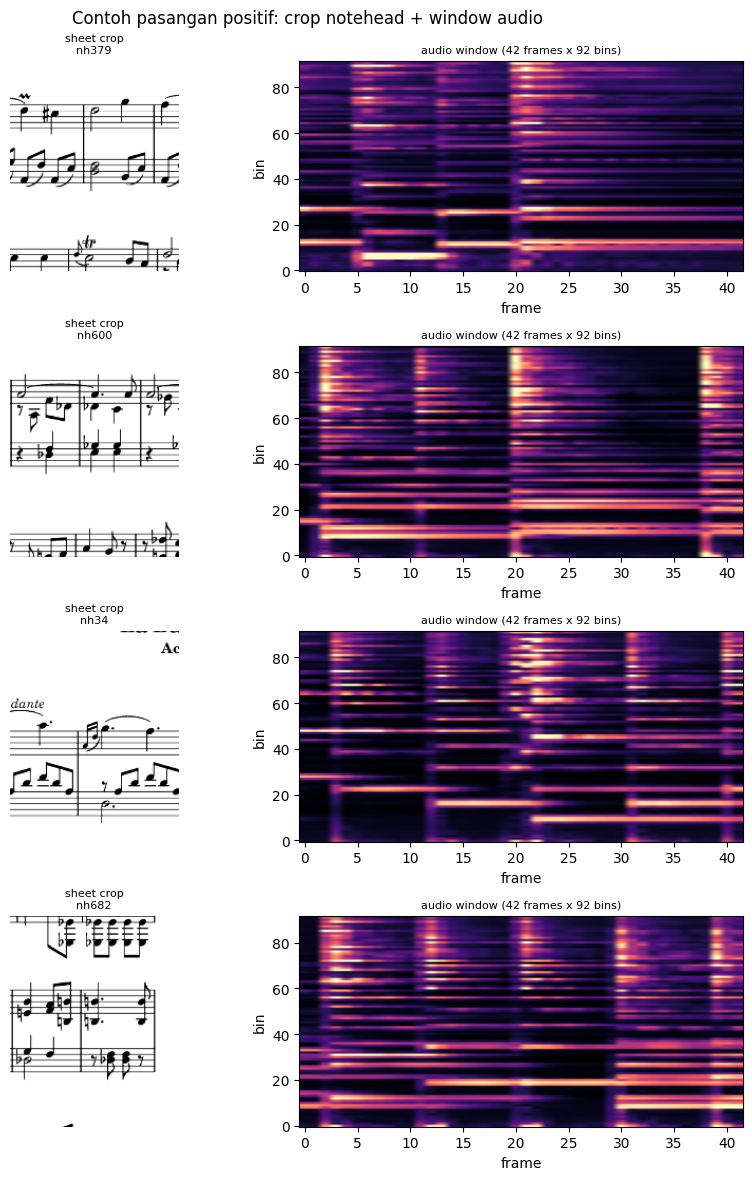

In [6]:
sample = positives["train"].sample(n=4, random_state=SEED).reset_index(drop=True)
crops_train = np.load(DATA_DIR / "score_crops_train.npy", mmap_mode="r")
windows_train = np.load(DATA_DIR / "audio_windows_train.npy", mmap_mode="r")

fig, axes = plt.subplots(4, 2, figsize=(9, 12))
for row_index, (_, row) in enumerate(sample.iterrows()):
    image = crops_train[int(row["crop_row"])][..., 0]
    spec = np.asarray(windows_train[int(row["window_row_eval"])])
    axes[row_index, 0].imshow(image, cmap="gray")
    axes[row_index, 0].set_title(f"sheet crop\n{row['notehead_id'].split('__')[-1]}", fontsize=8)
    axes[row_index, 0].axis("off")
    vmin, vmax = np.percentile(spec, [1, 99])
    axes[row_index, 1].imshow(spec.T, origin="lower", aspect="auto", cmap="magma", vmin=vmin, vmax=vmax)
    axes[row_index, 1].set_title("audio window (42 frames x 92 bins)", fontsize=8)
    axes[row_index, 1].set_xlabel("frame")
    axes[row_index, 1].set_ylabel("bin")
fig.suptitle("Contoh pasangan positif: crop notehead + window audio")
fig.tight_layout()
fig.savefig(FIG_DIR / "20_baseline_task1_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Dataset

Positive pairs core; augmentasi image scale/translate + audio shift/tempo jitter.

In [7]:
train_pairs = positives["train"]
val_pairs = one_window_per_notehead(positives["val"])

train_dataset = PositivePairDataset(
    DATA_DIR / "score_crops_train.npy",
    DATA_DIR / "audio_windows_train.npy",
    train_pairs["crop_row"].to_numpy(),
    train_pairs["window_row_eval"].to_numpy(),
    augment=True,
    **CONFIG["augment"],
)
val_dataset = PositivePairDataset(
    DATA_DIR / "score_crops_val.npy",
    DATA_DIR / "audio_windows_val.npy",
    val_pairs["crop_row"].to_numpy(),
    val_pairs["window_row_eval"].to_numpy(),
    augment=False,
    **CONFIG["augment"],
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    drop_last=False,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["eval_batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
)

images, specs = next(iter(train_loader))
print("batch image:", tuple(images.shape), images.dtype)
print("batch audio:", tuple(specs.shape), specs.dtype)
assert images.shape[1:] == (1, 100, 80)
assert specs.shape[1:] == (1, 92, 42)
assert torch.isfinite(images).all() and torch.isfinite(specs).all()
print(f"train batches: {len(train_loader):,} | val pairs: {len(val_dataset):,}")

batch image: (128, 1, 100, 80) torch.float32
batch audio: (128, 1, 92, 42) torch.float32
train batches: 225 | val pairs: 2,430


## 5. Model

`DualEncoder` dengan channel 16/32/64 dan `use_cca=False`.

In [8]:
model = DualEncoder(
    embed_dim=CONFIG["embed_dim"],
    use_cca=CONFIG["use_cca"],
    cca_kwargs=CONFIG["cca"],
    channels=CONFIG["channels"],
).to(DEVICE)

print(f"Total parameters: {count_parameters(model):,}")
print(f"Trainable       : {count_parameters(model, trainable_only=True):,}")
print(model)

model.eval()
with torch.no_grad():
    z_sheet_dummy, z_audio_dummy = model(images[:4].to(DEVICE), specs[:4].to(DEVICE))
print("z_sheet:", tuple(z_sheet_dummy.shape), "| norm:", z_sheet_dummy.norm(dim=1).cpu().numpy())
print("z_audio:", tuple(z_audio_dummy.shape), "| norm:", z_audio_dummy.norm(dim=1).cpu().numpy())
model.train()

Total parameters: 148,256
Trainable       : 148,256
DualEncoder(
  (sheet): SheetEncoder(
    (blocks): Sequential(
      (0): ConvStack(
        (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act): ELU(alpha=1.0, inplace=True)
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (1): ConvStack(
        (conv1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


DualEncoder(
  (sheet): SheetEncoder(
    (blocks): Sequential(
      (0): ConvStack(
        (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act): ELU(alpha=1.0, inplace=True)
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (1): ConvStack(
        (conv1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0

## 6. Training

Adam 2e-3; 6 epoch; early stop 3; model selection MRR validasi.

In [9]:
criterion = RankingLoss(margin=CONFIG["margin"])
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=CONFIG["lr"],
    weight_decay=CONFIG["weight_decay"],
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
)

def train_one_epoch(model, loader, optimizer, criterion, device, grad_clip):
    model.train()
    total_loss = 0.0
    total_items = 0
    for images, specs in loader:
        images = images.to(device, non_blocking=True)
        specs = specs.to(device, non_blocking=True)
        z_sheet, z_audio = model(images, specs)
        loss = criterion(z_sheet, z_audio)
        if not torch.isfinite(loss):
            raise RuntimeError(
                "Loss tidak finite. Cek learning rate, data, atau stabilitas "
                "numerik model."
            )
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if grad_clip:
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        total_loss += float(loss.detach()) * images.size(0)
        total_items += images.size(0)
    return total_loss / max(total_items, 1)

@torch.no_grad()
def evaluate_val_mrr(model, loader, device):
    model.eval()
    images_all, specs_all = [], []
    for images, specs in loader:
        images_all.append(images)
        specs_all.append(specs)
    images_all = torch.cat(images_all, dim=0).to(device)
    specs_all = torch.cat(specs_all, dim=0).to(device)
    z_sheet, z_audio = model(images_all, specs_all)
    scores = (z_sheet @ z_audio.T).float().cpu().numpy()
    if not np.isfinite(scores).all():
        return {
            "mrr_a2s": float("nan"),
            "mrr_s2a": float("nan"),
            "mrr_mean": float("nan"),
            "n": int(scores.shape[0]),
        }
    targets = np.arange(scores.shape[0])
    ranks_a2s = ranks_from_scores(scores, targets)
    ranks_s2a = ranks_from_scores(scores.T, targets)
    mrr_a2s = float((1.0 / ranks_a2s).mean())
    mrr_s2a = float((1.0 / ranks_s2a).mean())
    return {
        "mrr_a2s": mrr_a2s,
        "mrr_s2a": mrr_s2a,
        "mrr_mean": 0.5 * (mrr_a2s + mrr_s2a),
        "n": int(scores.shape[0]),
    }

In [10]:
def fit(model, train_loader, val_loader, optimizer, scheduler, criterion,
        config, device, checkpoint_path):
    history = []
    best_mrr = -1.0
    bad_epochs = 0
    for epoch in range(1, int(config["epochs"]) + 1):
        started = time.time()
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion, device, config["grad_clip"]
        )
        val_metrics = evaluate_val_mrr(model, val_loader, device)
        if not np.isfinite(val_metrics["mrr_mean"]):
            print("Val MRR tidak finite; training dihentikan. Cek stabilitas CCA/numerik.")
            break
        scheduler.step(val_metrics["mrr_mean"])
        elapsed = time.time() - started
        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            **val_metrics,
            "lr": float(optimizer.param_groups[0]["lr"]),
            "seconds": elapsed,
        }
        history.append(record)
        print(
            f"epoch {epoch:02d} | loss {train_loss:.4f} | "
            f"val MRR A2S {val_metrics['mrr_a2s']:.4f} | "
            f"val MRR S2A {val_metrics['mrr_s2a']:.4f} | "
            f"lr {record['lr']:.2e} | {elapsed:.1f}s"
        )
        if val_metrics["mrr_mean"] > best_mrr:
            best_mrr = val_metrics["mrr_mean"]
            bad_epochs = 0
            torch.save(
                {
                    "model_state": model.state_dict(),
                    "sheet_encoder": model.sheet.state_dict(),
                    "audio_encoder": model.audio.state_dict(),
                    "config": config,
                    "epoch": epoch,
                    "val_metrics": val_metrics,
                },
                checkpoint_path,
            )
            print(f"  -> checkpoint disimpan (best val MRR {best_mrr:.4f})")
        else:
            bad_epochs += 1
            if bad_epochs >= int(config["early_stop_patience"]):
                print(f"Early stop setelah {bad_epochs} epoch tanpa perbaikan.")
                break
    return history, best_mrr

## 7. Jalankan training

In [11]:
FAST_DEV_RUN = bool(CONFIG["fast_dev"])
run_train_loader = train_loader
run_val_loader = val_loader
run_epochs = int(CONFIG["epochs"])
run_patience = int(CONFIG["early_stop_patience"])

if FAST_DEV_RUN:
    run_train_loader = DataLoader(
        Subset(train_dataset, range(min(2000, len(train_dataset)))),
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        num_workers=CONFIG["num_workers"],
    )
    run_val_loader = DataLoader(
        Subset(val_dataset, range(min(500, len(val_dataset)))),
        batch_size=CONFIG["eval_batch_size"],
        shuffle=False,
        num_workers=CONFIG["num_workers"],
    )
    run_epochs = 2
    run_patience = 2
    print("FAST_DEV_RUN aktif: 2.000 train pairs, 500 val pairs, 2 epoch.")

fit_config = dict(CONFIG)
fit_config["epochs"] = run_epochs
fit_config["early_stop_patience"] = run_patience

checkpoint_path = CKPT_DIR / "baseline_task1_dual_encoder.pt"
history, best_mrr = fit(
    model,
    run_train_loader,
    run_val_loader,
    optimizer,
    scheduler,
    criterion,
    fit_config,
    DEVICE,
    checkpoint_path,
)
print(f"Best validation MRR: {best_mrr:.4f}")
print("Checkpoint:", checkpoint_path)

epoch 01 | loss 0.2296 | val MRR A2S 0.0045 | val MRR S2A 0.0034 | lr 2.00e-03 | 233.4s
  -> checkpoint disimpan (best val MRR 0.0040)


epoch 02 | loss 0.1311 | val MRR A2S 0.0049 | val MRR S2A 0.0046 | lr 2.00e-03 | 188.0s
  -> checkpoint disimpan (best val MRR 0.0048)


epoch 03 | loss 0.1038 | val MRR A2S 0.0035 | val MRR S2A 0.0072 | lr 2.00e-03 | 185.5s
  -> checkpoint disimpan (best val MRR 0.0054)


epoch 04 | loss 0.0839 | val MRR A2S 0.0081 | val MRR S2A 0.0053 | lr 2.00e-03 | 185.1s
  -> checkpoint disimpan (best val MRR 0.0067)


epoch 05 | loss 0.0695 | val MRR A2S 0.0069 | val MRR S2A 0.0028 | lr 2.00e-03 | 184.1s


epoch 06 | loss 0.0588 | val MRR A2S 0.0092 | val MRR S2A 0.0081 | lr 2.00e-03 | 181.6s
  -> checkpoint disimpan (best val MRR 0.0086)
Best validation MRR: 0.0086
Checkpoint: <project-root>\checkpoints\baseline_task1_dual_encoder.pt


,epoch,train_loss,mrr_a2s,mrr_s2a,mrr_mean,n,lr,seconds
0,1,0.229620,0.004474,0.003438,0.003956,2430,0.002,233.352659
1,2,0.131141,0.004927,0.004580,0.004753,2430,0.002,187.964294
2,3,0.103805,0.003524,0.007189,0.005356,2430,0.002,185.473594
3,4,0.083858,0.008077,0.005293,0.006685,2430,0.002,185.113038
4,5,0.069454,0.006899,0.002816,0.004857,2430,0.002,184.062185
5,6,0.058779,0.009223,0.008064,0.008644,2430,0.002,181.576955


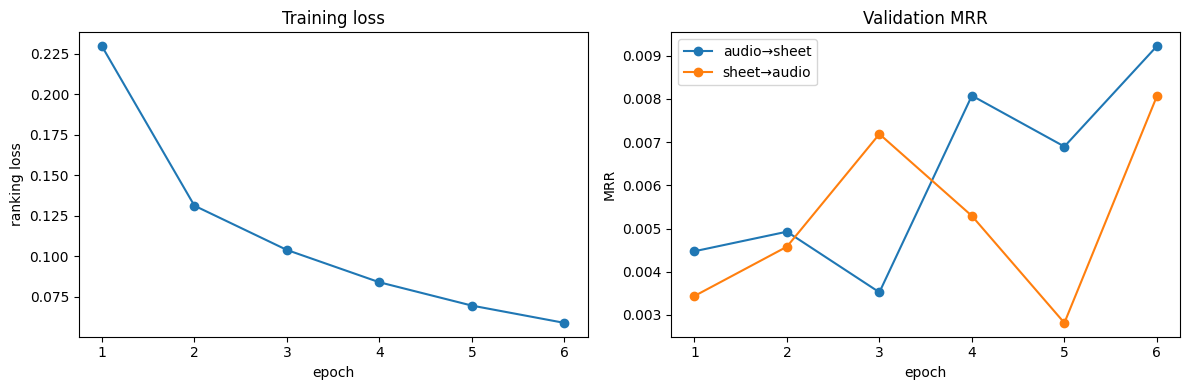

In [12]:
history_df = pd.DataFrame(history)
display(history_df)
history_df.to_csv(REPORTS_DIR / "baseline_task1_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("ranking loss")
axes[0].set_title("Training loss")
axes[1].plot(history_df["epoch"], history_df["mrr_a2s"], marker="o", label="audio→sheet")
axes[1].plot(history_df["epoch"], history_df["mrr_s2a"], marker="o", label="sheet→audio")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("MRR")
axes[1].set_title("Validation MRR")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "21_baseline_task1_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Evaluasi snippet retrieval

R@1/5/10/25, MRR, median rank; paired dan extended.

In [13]:
checkpoint = load_checkpoint(CKPT_DIR / "baseline_task1_dual_encoder.pt", map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()
print("Loaded epoch", checkpoint.get("epoch"), "| val:", checkpoint.get("val_metrics"))

noteheads_test, windows_test, pairs_test = frames["test"]
noteheads_test = noteheads_test.sort_values("crop_row").reset_index(drop=True)
windows_test = windows_test.sort_values("window_row").reset_index(drop=True)
assert np.array_equal(
    noteheads_test["crop_row"].to_numpy(), np.arange(len(noteheads_test))
)
assert np.array_equal(
    windows_test["window_row"].to_numpy(), np.arange(len(windows_test))
)
notehead_ids = noteheads_test["notehead_id"].tolist()
notehead_to_index = {notehead_id: index for index, notehead_id in enumerate(notehead_ids)}

sheet_hidden = embed_image_rows(
    model.sheet,
    DATA_DIR / "score_crops_test.npy",
    noteheads_test["crop_row"].to_numpy(),
    batch_size=CONFIG["eval_batch_size"],
    device=DEVICE,
)
audio_hidden = embed_audio_rows(
    model.audio,
    DATA_DIR / "audio_windows_test.npy",
    windows_test["window_row"].to_numpy(),
    batch_size=CONFIG["eval_batch_size"],
    device=DEVICE,
)

if model.cca is not None:
    z_sheet = project_cca(
        sheet_hidden.to(DEVICE),
        model.cca.mean1.detach(),
        model.cca.U.detach(),
    ).cpu()
    z_audio = project_cca(
        audio_hidden.to(DEVICE),
        model.cca.mean2.detach(),
        model.cca.V.detach(),
    ).cpu()
else:
    z_sheet = F.normalize(sheet_hidden, dim=1)
    z_audio = F.normalize(audio_hidden, dim=1)

print("z_sheet:", tuple(z_sheet.shape), "| z_audio:", tuple(z_audio.shape))
assert z_sheet.shape == (len(noteheads_test), CONFIG["embed_dim"])
assert z_audio.shape == (len(windows_test), CONFIG["embed_dim"])
assert torch.isfinite(z_sheet).all() and torch.isfinite(z_audio).all()

Loaded epoch 6 | val: {'mrr_a2s': 0.009223142917489378, 'mrr_s2a': 0.008063890564363718, 'mrr_mean': 0.008643516740926548, 'n': 2430}


z_sheet: (2018, 32) | z_audio: (8072, 32)


In [14]:
similarity = (z_audio @ z_sheet.T).numpy()
assert np.isfinite(similarity).all()
window_targets = windows_test["notehead_id"].map(notehead_to_index).to_numpy()
assert not np.isnan(window_targets).any()
window_targets = window_targets.astype(int)

paired = one_window_per_notehead(
    build_positive_pairs(pairs_test, noteheads_test, windows_test)
)
paired_window_rows = paired["window_row_eval"].to_numpy()
paired_targets = paired["notehead_id"].map(notehead_to_index).to_numpy().astype(int)
assert len(paired) == len(noteheads_test)
assert np.array_equal(np.sort(paired_targets), np.arange(len(noteheads_test)))

similarity_paired = similarity[paired_window_rows]
ranks_paired_a2s = ranks_from_scores(similarity_paired, paired_targets)

inverse_paired_targets = np.empty_like(paired_targets)
inverse_paired_targets[paired_targets] = np.arange(len(paired_targets))
ranks_paired_s2a = ranks_from_scores(similarity_paired.T, inverse_paired_targets)

ranks_extended_a2s = ranks_from_scores(similarity, window_targets)
target_lists = [
    np.flatnonzero(window_targets == index) for index in range(len(noteheads_test))
]
ranks_extended_s2a = ranks_from_multi_scores(similarity.T, target_lists)

rng = np.random.default_rng(SEED)
shuffled_queries = rng.permutation(len(paired))
ranks_random = ranks_from_scores(
    similarity_paired[shuffled_queries],
    paired_targets,
)

snippet_metrics = {
    "paired_2018_audio_to_sheet": retrieval_metrics(ranks_paired_a2s),
    "paired_2018_sheet_to_audio": retrieval_metrics(ranks_paired_s2a),
    "extended_audio_to_sheet": retrieval_metrics(ranks_extended_a2s),
    "extended_sheet_to_audio": retrieval_metrics(ranks_extended_s2a),
    "random_paired_audio_to_sheet": retrieval_metrics(ranks_random),
}
display(
    pd.DataFrame({
        "protocol": list(snippet_metrics.keys()),
        **{
            metric: [value.get(metric) for value in snippet_metrics.values()]
            for metric in ("R@1", "R@5", "R@10", "R@25", "MRR", "median_rank")
        },
    })
)

protocol,R@1,R@5,R@10,R@25,MRR,median_rank
paired_2018_audio_to_sheet,0.001487,0.008424,0.013380,0.030723,0.008724,573.5
paired_2018_sheet_to_audio,0.000991,0.004955,0.016353,0.039148,0.009160,526.0
extended_audio_to_sheet,0.001982,0.009663,0.017096,0.039148,0.010537,515.0
extended_sheet_to_audio,0.002973,0.004955,0.015362,0.035183,0.009004,826.5
random_paired_audio_to_sheet,0.000496,0.002478,0.005451,0.017839,0.004390,1018.5


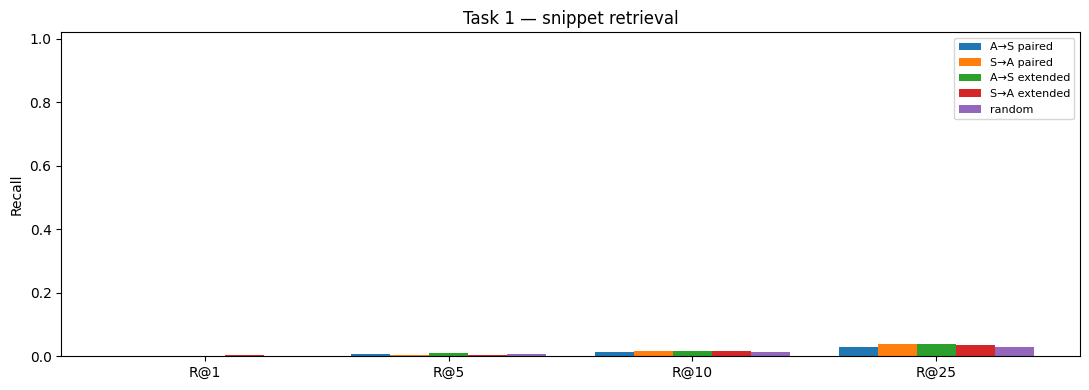

In [15]:
metric_keys = ["R@1", "R@5", "R@10", "R@25"]
column_keys = [
    "paired_2018_audio_to_sheet",
    "paired_2018_sheet_to_audio",
    "extended_audio_to_sheet",
    "extended_sheet_to_audio",
    "random_paired_audio_to_sheet",
]
column_labels = ["A→S paired", "S→A paired", "A→S extended", "S→A extended", "random"]

x = np.arange(len(metric_keys))
width = 0.16
fig, ax = plt.subplots(figsize=(11, 4))
for index, (key, label) in enumerate(zip(column_keys, column_labels)):
    values = [snippet_metrics[key].get(metric, 0.0) for metric in metric_keys]
    ax.bar(x + (index - 2) * width, values, width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(metric_keys)
ax.set_ylim(0, 1.02)
ax.set_ylabel("Recall")
ax.set_title("Task 1 — snippet retrieval")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "22_baseline_task1_snippet_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. System localization

Page-conditioned, full collection, dan 5-candidate.

In [16]:
nh_systems = pd.read_parquet(DATA_DIR / "notehead_systems_test.parquet")
systems = pd.read_parquet(DATA_DIR / "systems_test.parquet")
pairs_system = pd.read_parquet(DATA_DIR / "pairs_system_test.parquet")

system_ids = systems["system_id"].tolist()
system_to_col = {system_id: index for index, system_id in enumerate(system_ids)}
assert pairs_system["candidate_system_id"].isin(system_ids).all()
assert pairs_system["positive_system_id"].isin(system_ids).all()
nh_systems["notehead_index"] = nh_systems["notehead_id"].map(notehead_to_index)
assert nh_systems["notehead_index"].notna().all()
nh_systems["notehead_index"] = nh_systems["notehead_index"].astype(int)

system_notehead_indices = {
    system_id: nh_systems.loc[
        nh_systems["system_id"] == system_id, "notehead_index"
    ].to_numpy()
    for system_id in system_ids
}
system_scores = np.full((len(windows_test), len(system_ids)), -np.inf, dtype=np.float32)
for system_id, indices in system_notehead_indices.items():
    if len(indices):
        system_scores[:, system_to_col[system_id]] = similarity[:, indices].max(axis=1)

notehead_to_system = nh_systems.set_index("notehead_id")["system_id"].to_dict()
window_true_system = windows_test["notehead_id"].map(notehead_to_system)
assert window_true_system.notna().all()
window_true_system_col = window_true_system.map(system_to_col).to_numpy().astype(int)

In [17]:
ranks_system_full = ranks_from_scores(system_scores, window_true_system_col)

page_to_systems = systems.groupby("page_id")["system_id"].apply(list).to_dict()
window_pages = windows_test["page_id"].to_numpy()
ranks_system_page = np.empty(len(windows_test), dtype=np.int64)
for index in range(len(windows_test)):
    candidate_systems = page_to_systems[window_pages[index]]
    candidate_cols = np.asarray([system_to_col[s] for s in candidate_systems], dtype=int)
    true_col = window_true_system_col[index]
    assert true_col in candidate_cols, "True system tidak ada di halaman query."
    scores = system_scores[index, candidate_cols]
    true_score = system_scores[index, true_col]
    ranks_system_page[index] = int((scores > true_score).sum()) + 1

ranks_system_5 = []
for _, group in pairs_system.groupby("query_id", sort=False):
    row = int(group["window_row"].iloc[0])
    candidate_cols = group["candidate_system_id"].map(system_to_col).to_numpy()
    scores = system_scores[row, candidate_cols]
    positive_id = group.loc[group["label"] == 1, "candidate_system_id"].iloc[0]
    positive_position = int(
        np.flatnonzero(group["candidate_system_id"].to_numpy() == positive_id)[0]
    )
    ranks_system_5.append(int((scores > scores[positive_position]).sum()) + 1)
ranks_system_5 = np.asarray(ranks_system_5)

system_metrics = {
    "page_conditioned": retrieval_metrics(ranks_system_page),
    "full_collection": retrieval_metrics(ranks_system_full),
    "five_candidate": retrieval_metrics(ranks_system_5),
}
display(pd.DataFrame(system_metrics).T)

,R@1,R@5,R@10,R@25,MRR,median_rank,mean_rank,n_queries
page_conditioned,0.275025,0.944623,1.000000,1.000000,0.515240,3.0,2.792616,8072.0
full_collection,0.076189,0.253964,0.438429,0.823464,0.187559,13.0,14.181120,8072.0
five_candidate,0.255575,1.000000,1.000000,1.000000,0.519109,2.0,2.585976,8072.0


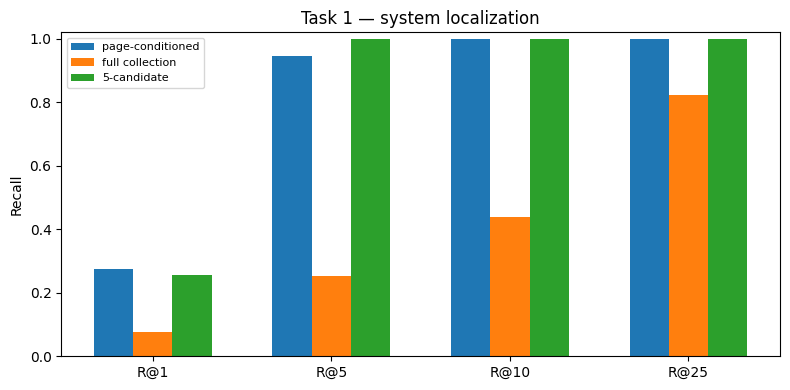

In [18]:
metric_keys = ["R@1", "R@5", "R@10", "R@25"]
protocol_labels = ["page-conditioned", "full collection", "5-candidate"]
protocol_keys = ["page_conditioned", "full_collection", "five_candidate"]

x = np.arange(len(metric_keys))
width = 0.22
fig, ax = plt.subplots(figsize=(8, 4))
for index, (key, label) in enumerate(zip(protocol_keys, protocol_labels)):
    values = [system_metrics[key].get(metric, 0.0) for metric in metric_keys]
    ax.bar(x + (index - 1) * width, values, width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(metric_keys)
ax.set_ylim(0, 1.02)
ax.set_ylabel("Recall")
ax.set_title("Task 1 — system localization")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "23_baseline_task1_system_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Piece/page identification

Voting top-25 snippet.

In [19]:
notehead_piece = noteheads_test["piece"].to_numpy()
notehead_page = noteheads_test["page_id"].to_numpy()
window_piece = windows_test["piece"].to_numpy()
window_page = windows_test["page_id"].to_numpy()

piece_names = sorted(set(window_piece))
piece_to_id = {name: index for index, name in enumerate(piece_names)}
page_names = sorted(set(window_page))
page_to_id = {name: index for index, name in enumerate(page_names)}

def vote_rank(labels_per_candidate, true_label, label_to_id, num_labels):
    votes = np.zeros(num_labels, dtype=np.int64)
    for label in labels_per_candidate:
        votes[label_to_id[label]] += 1
    true_id = label_to_id[true_label]
    order = np.argsort(-votes, kind="stable")
    return int(np.flatnonzero(order == true_id)[0]) + 1

top_k = 25
top_noteheads = np.argsort(-similarity, axis=1)[:, :top_k]
ranks_piece_a2s, ranks_page_a2s = [], []
for index in range(len(windows_test)):
    candidate_ids = top_noteheads[index]
    ranks_piece_a2s.append(
        vote_rank(notehead_piece[candidate_ids], window_piece[index], piece_to_id, len(piece_names))
    )
    ranks_page_a2s.append(
        vote_rank(notehead_page[candidate_ids], window_page[index], page_to_id, len(page_names))
    )

top_windows = np.argsort(-similarity.T, axis=1)[:, :top_k]
ranks_piece_s2a, ranks_page_s2a = [], []
for index in range(len(noteheads_test)):
    candidate_ids = top_windows[index]
    ranks_piece_s2a.append(
        vote_rank(window_piece[candidate_ids], notehead_piece[index], piece_to_id, len(piece_names))
    )
    ranks_page_s2a.append(
        vote_rank(window_page[candidate_ids], notehead_page[index], page_to_id, len(page_names))
    )

identification_metrics = {
    "piece_audio_to_sheet_top25": hit_rate_at_k(ranks_piece_a2s),
    "piece_sheet_to_audio_top25": hit_rate_at_k(ranks_piece_s2a),
    "page_audio_to_sheet_top25": hit_rate_at_k(ranks_page_a2s),
    "page_sheet_to_audio_top25": hit_rate_at_k(ranks_page_s2a),
}
display(pd.DataFrame(identification_metrics).T)

,Rk@1,Rk@1_pct,Rk@5,Rk@5_pct,Rk@10,Rk@10_pct,n_queries
piece_audio_to_sheet_top25,3604.0,0.446482,8072.0,1.000000,8072.0,1.0,8072.0
piece_sheet_to_audio_top25,1247.0,0.617939,2018.0,1.000000,2018.0,1.0,2018.0
page_audio_to_sheet_top25,2309.0,0.286051,6209.0,0.769202,8072.0,1.0,8072.0
page_sheet_to_audio_top25,759.0,0.376115,1768.0,0.876115,2018.0,1.0,2018.0


## 11. Contoh kualitatif

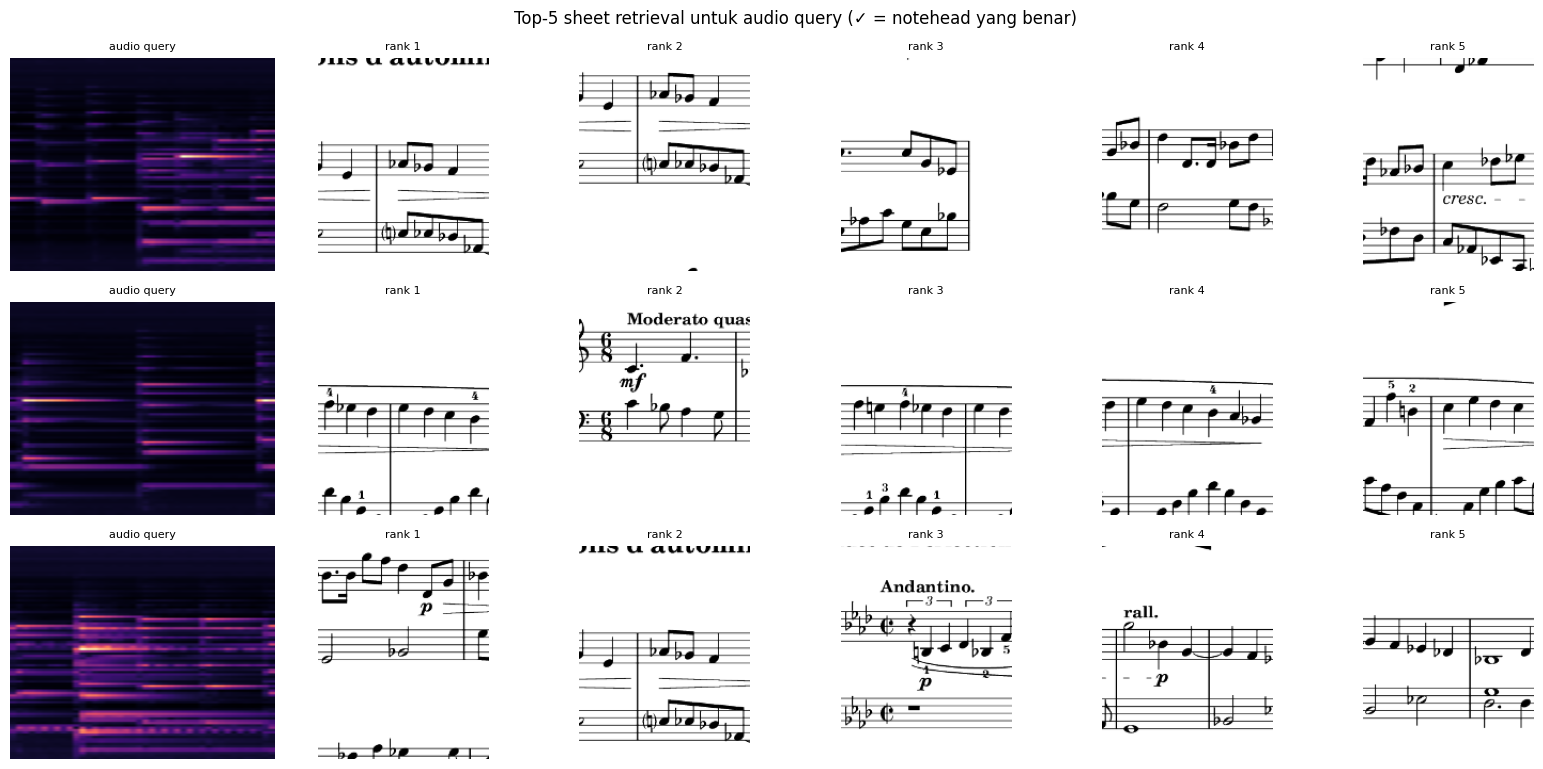

In [20]:
query_indices = windows_test.groupby("piece").head(1).index.to_list()[:4]
crops_test = np.load(DATA_DIR / "score_crops_test.npy", mmap_mode="r")
windows_test_array = np.load(DATA_DIR / "audio_windows_test.npy", mmap_mode="r")

fig, axes = plt.subplots(len(query_indices), 6, figsize=(16, 2.6 * len(query_indices)))
if len(query_indices) == 1:
    axes = np.expand_dims(axes, axis=0)
for row_index, query_index in enumerate(query_indices):
    spec = np.asarray(windows_test_array[int(query_index)])
    axes[row_index, 0].imshow(spec.T, origin="lower", aspect="auto", cmap="magma")
    axes[row_index, 0].set_title("audio query", fontsize=8)
    axes[row_index, 0].axis("off")

    top_indices = np.argsort(-similarity[int(query_index)])[:5]
    true_index = int(window_targets[int(query_index)])
    for rank, candidate_index in enumerate(top_indices, start=1):
        crop_row = int(noteheads_test.iloc[int(candidate_index)]["crop_row"])
        image = crops_test[crop_row][..., 0]
        axes[row_index, rank].imshow(image, cmap="gray")
        is_correct = int(candidate_index) == true_index
        axes[row_index, rank].set_title(
            f"rank {rank}" + (" ✓" if is_correct else ""),
            fontsize=8,
            color="green" if is_correct else "black",
        )
        axes[row_index, rank].axis("off")
fig.suptitle("Top-5 sheet retrieval untuk audio query (✓ = notehead yang benar)")
fig.tight_layout()
fig.savefig(FIG_DIR / "24_baseline_task1_top5.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Simpan hasil

In [21]:
metrics_payload = {
    "paper": "Dorfer et al. (2018), TISMIR 1(1):22-33",
    "task": "Task 1 - score-audio alignment / system localization",
    "config": CONFIG,
    "seed": SEED,
    "device": str(DEVICE),
    "checkpoint": str(CKPT_DIR / "baseline_task1_dual_encoder.pt"),
    "best_checkpoint_epoch": checkpoint.get("epoch"),
    "best_val_metrics": checkpoint.get("val_metrics"),
    "snippet_retrieval": snippet_metrics,
    "system_localization": system_metrics,
    "identification": identification_metrics,
    "history": history,
}
save_json(REPORTS_DIR / "baseline_task1_metrics.json", metrics_payload)

np.savez_compressed(
    CKPT_DIR / "baseline_task1_test_embeddings.npz",
    sheet=z_sheet.numpy(),
    audio=z_audio.numpy(),
    notehead_ids=np.asarray(notehead_ids),
    window_ids=windows_test["window_id"].to_numpy(),
)
print("Disimpan:", REPORTS_DIR / "baseline_task1_metrics.json")
print("Disimpan:", CKPT_DIR / "baseline_task1_test_embeddings.npz")

Disimpan: <project-root>\reports\baseline_task1_metrics.json
Disimpan: <project-root>\checkpoints\baseline_task1_test_embeddings.npz


## 13. Catatan

Pilot 17 train pieces; snippet retrieval lemah; system localization sedikit di atas random.